<a href="https://colab.research.google.com/github/2303a510b9/Quantum-Computing-Hackathon/blob/main/Question%20no%2012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
%%bash
pip install -q pennylane torch scikit-learn matplotlib seaborn

### Quantum Classifier Implementation with Data Re-uploading

We will construct a quantum classifier where classical inputs are re-uploaded at every layer alongside trainable variational weights. We will evaluate this architecture on:
1. **Iris Dataset** (mapped to a binary classification task)
2. **Two Moons Dataset** (non-linear 2D dataset)

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import pennylane as qml
from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, roc_auc_score, classification_report
)

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Configuration
N_QUBITS = 2
LAYERS = 3
dev = qml.device("default.qubit", wires=N_QUBITS)

# Tracking forward circuit evaluations
circuit_evals = 0

def state_prep_and_layer(inputs, weights):
    # Re-uploading: Encode inputs and apply trainable rotations
    for l in range(LAYERS):
        for i in range(N_QUBITS):
            # Linear combination of features (we expect 2-dimensional features scaled to [-pi, pi])
            qml.RX(inputs[i % len(inputs)] + weights[l, i, 0], wires=i)
            qml.RY(inputs[i % len(inputs)] + weights[l, i, 1], wires=i)
            qml.RZ(inputs[i % len(inputs)] + weights[l, i, 2], wires=i)
        # Entangling layer
        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
        if N_QUBITS > 2:
            qml.CNOT(wires=[N_QUBITS - 1, 0])

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    global circuit_evals
    circuit_evals += 1
    state_prep_and_layer(inputs, weights)
    # Expectation value of PauliZ on the first qubit for binary output
    return qml.expval(qml.PauliZ(0))

# Obtain logical circuit depth using PennyLane specs
inputs_dummy = torch.tensor([0.1, 0.2], dtype=torch.float32)
weights_dummy = torch.randn(LAYERS, N_QUBITS, 3, dtype=torch.float32)
specs = qml.specs(quantum_circuit)(inputs_dummy, weights_dummy)

# Access logical depth correctly via the resources object in modern PennyLane versions
logical_depth = specs['resources'].depth
print(f"Logical Circuit Depth: {logical_depth}")

Logical Circuit Depth: 12


In [11]:
def train_and_evaluate(X, y, dataset_name):
    global circuit_evals
    circuit_evals = 0

    # Scale data to [-pi, pi] for quantum angle encoding
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    X_scaled = scaler.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.3, random_state=42, stratify=y
    )

    # Convert to PyTorch Tensors
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32)

    # Weights parameters: shape [LAYERS, N_QUBITS, 3 rotations]
    weights = torch.randn(LAYERS, N_QUBITS, 3, dtype=torch.float32, requires_grad=True)
    optimizer = optim.Adam([weights], lr=0.1)

    # Training loop
    epochs = 40
    start_train_time = time.perf_counter()
    training_evals_before = circuit_evals

    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = 0.0
        for x_val, y_val in zip(X_train_t, y_train_t):
            # Model output mapped from [-1, 1] to a sigmoidal probability
            out = quantum_circuit(x_val, weights)
            prob = torch.sigmoid(3.0 * out)
            loss += - (y_val * torch.log(prob + 1e-8) + (1.0 - y_val) * torch.log(1.0 - prob + 1e-8))
        loss /= len(X_train_t)
        loss.backward()
        optimizer.step()

    end_train_time = time.perf_counter()
    training_time = end_train_time - start_train_time
    training_evaluations = circuit_evals - training_evals_before

    # Inference evaluation
    start_inf_time = time.perf_counter()
    inference_evals_before = circuit_evals

    y_pred_probs = []
    with torch.no_grad():
        for x_val in X_test_t:
            out = quantum_circuit(x_val, weights)
            prob = torch.sigmoid(3.0 * out).item()
            y_pred_probs.append(prob)

    end_inf_time = time.perf_counter()
    inference_time = end_inf_time - start_inf_time
    inference_evaluations = circuit_evals - inference_evals_before

    y_pred = np.array([1 if p >= 0.5 else 0 for p in y_pred_probs])
    y_test_np = y_test_t.numpy()

    # Metrics
    acc = accuracy_score(y_test_np, y_pred)
    bal_acc = balanced_accuracy_score(y_test_np, y_pred)
    f1 = f1_score(y_test_np, y_pred, average='macro')
    auc = roc_auc_score(y_test_np, y_pred_probs)
    cm = confusion_matrix(y_test_np, y_pred)

    # Get logical circuit depth dynamically
    specs = qml.specs(quantum_circuit)(X_test_t[0], weights)
    dyn_logical_depth = specs['resources'].depth

    print(f"\n{'='*10} DATASET: {dataset_name} {'='*10}")
    print("\nCLASSIFICATION RESULTS")
    print("Accuracy:", round(acc, 4))
    print("Balanced Accuracy:", round(bal_acc, 4))
    print("Macro F1 Score:", round(f1, 4))
    print("AUROC:", round(auc, 4))
    print("\nConfusion Matrix:\n", cm)
    print("\nClassification Report:\n", classification_report(y_test_np, y_pred))

    print("\nQUANTUM RESOURCE COST")
    print("Qubits:", N_QUBITS)
    print("Re-uploading layers:", LAYERS)
    print("Logical circuit depth (PennyLane specs):", dyn_logical_depth)
    print("Shots: Analytic simulation (no finite shots)")
    print("Training forward circuit evaluations:", training_evaluations)
    print("Inference circuit evaluations:", inference_evaluations)
    print("Training time:", round(training_time, 4), "seconds")
    print("Inference time:", round(inference_time, 4), "seconds")

    # Confusion Matrix Plotting
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
    plt.title(f"{dataset_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # Decision Boundary Visualization for 2D Datasets
    if X.shape[1] == 2:
        xx, yy = np.meshgrid(np.linspace(-np.pi, np.pi, 100), np.linspace(-np.pi, np.pi, 100))
        grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
        with torch.no_grad():
            zz = []
            for point in grid:
                out = quantum_circuit(point, weights)
                prob = torch.sigmoid(3.0 * out).item()
                zz.append(prob)
            zz = np.array(zz).reshape(xx.shape)

        plt.figure(figsize=(7, 6))
        plt.contourf(xx, yy, zz, levels=30, cmap="coolwarm", alpha=0.7)
        plt.colorbar(label="Probability of Class 1")
        plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y, cmap="coolwarm", edgecolors="k")
        plt.title(f"{dataset_name} - Decision Boundary")
        plt.xlabel("Feature 1 (scaled)")
        plt.ylabel("Feature 2 (scaled)")
        plt.tight_layout()
        plt.show()


========== DATASET: Iris (Binary classification) ==========

CLASSIFICATION RESULTS
Accuracy: 0.8889
Balanced Accuracy: 0.8667
Macro F1 Score: 0.8728
AUROC: 0.9489

Confusion Matrix:
 [[12  3]
 [ 2 28]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.86      0.80      0.83        15
         1.0       0.90      0.93      0.92        30

    accuracy                           0.89        45
   macro avg       0.88      0.87      0.87        45
weighted avg       0.89      0.89      0.89        45


QUANTUM RESOURCE COST
Qubits: 2
Re-uploading layers: 3
Logical circuit depth (PennyLane specs): 12
Shots: Analytic simulation (no finite shots)
Training forward circuit evaluations: 4200
Inference circuit evaluations: 45
Training time: 93.4312 seconds
Inference time: 1.2105 seconds


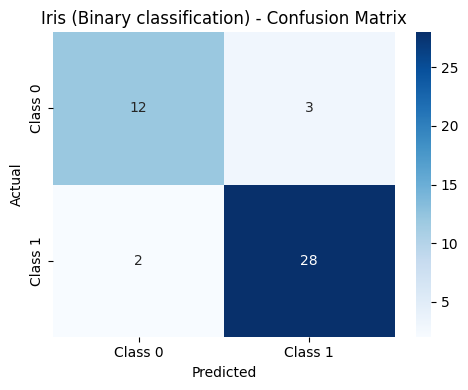

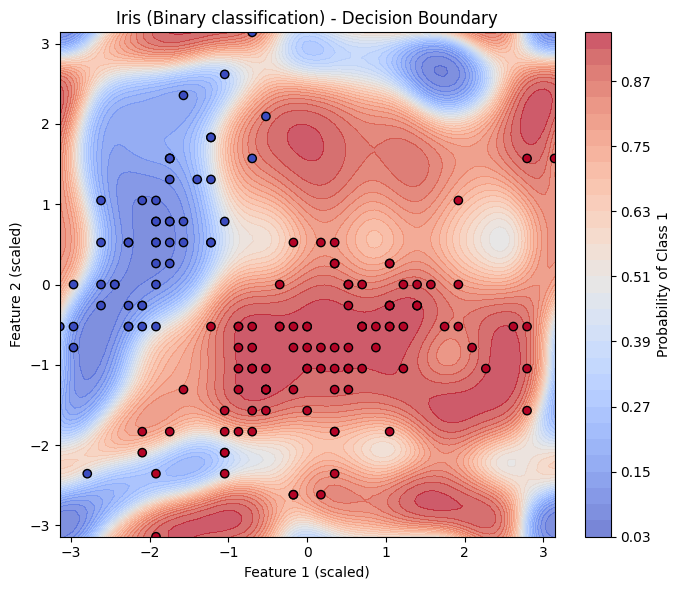

In [12]:
# 1. Prepare and run the Iris dataset (Binary classification task on Class 0 vs Class 1 & 2 combined)
iris = load_iris()
X_iris = iris.data[:, :2]  # We use the first 2 features to visualize boundary easier
y_iris = (iris.target != 0).astype(int)  # Binary classification

train_and_evaluate(X_iris, y_iris, "Iris (Binary classification)")


========== DATASET: Two Moons ==========

CLASSIFICATION RESULTS
Accuracy: 0.8167
Balanced Accuracy: 0.8167
Macro F1 Score: 0.8166
AUROC: 0.9256

Confusion Matrix:
 [[25  5]
 [ 6 24]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.81      0.83      0.82        30
         1.0       0.83      0.80      0.81        30

    accuracy                           0.82        60
   macro avg       0.82      0.82      0.82        60
weighted avg       0.82      0.82      0.82        60


QUANTUM RESOURCE COST
Qubits: 2
Re-uploading layers: 3
Logical circuit depth (PennyLane specs): 12
Shots: Analytic simulation (no finite shots)
Training forward circuit evaluations: 5600
Inference circuit evaluations: 60
Training time: 101.7295 seconds
Inference time: 0.3785 seconds


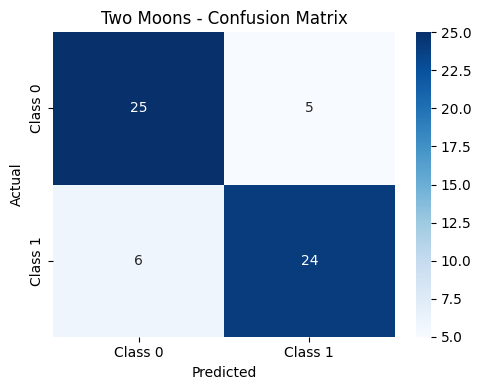

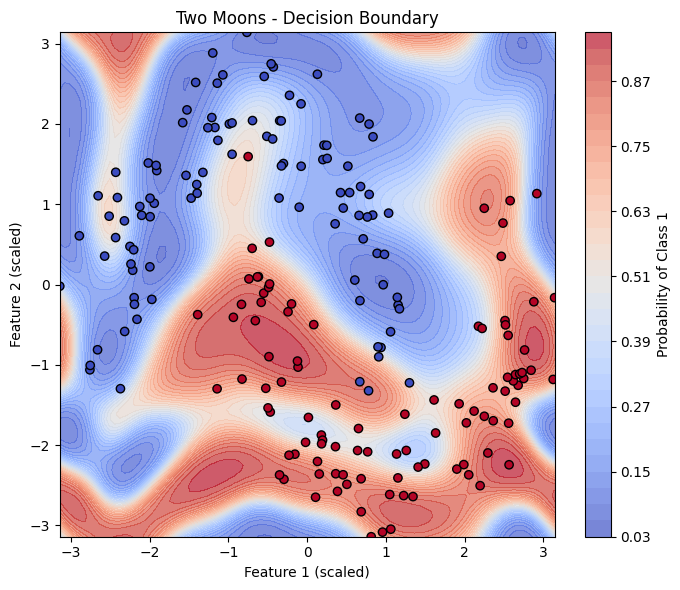

In [14]:
# 2. Prepare and run the Two Moons dataset
X_moons, y_moons = make_moons(n_samples=200, noise=0.15, random_state=42)
train_and_evaluate(X_moons, y_moons, "Two Moons")